# 1D Nonlinear Flows and Bifurcations

**References:** `Notes/lec10.pdf` (Lecture 10), `Notes/Reference_nonlinear_system.pptx`, `Notes/Problem Set II.pdf` (Q2, Q5)

## Concept & Formulas
Equation: $\frac{dx}{dt} = f(x)$.

- **Fixed points ($x^*$):** Points where $f(x^*) = 0$ (no change in $x$).
- **Stability test ($f'(x^*)$):**
  - $f'(x^*) < 0 \implies$ **Stable** (nearby trajectories move toward $x^*$).
  - $f'(x^*) > 0 \implies$ **Unstable** (nearby trajectories move away from $x^*$).
  - $f'(x^*) = 0 \implies$ **Linear test fails** (check the sign of $f(x)$ left and right of $x^*$, or plot $f(x)$ vs $x$).
- **Bifurcations** (when changing a parameter $r$ creates, destroys, or flips stability of fixed points):
  1. **Saddle-Node** ($\dot{x} = r + x^2$): fixed points appear/disappear in pairs.
  2. **Transcritical** ($\dot{x} = rx - x^2$): two fixed points collide and swap stability.
  3. **Pitchfork** ($\dot{x} = rx - x^3$): $x^*=0$ splits into 3 fixed points (or 2 new branches appear).
- **Limitations:** Simple Euler works well if $\Delta t$ is small enough, but sharp slopes can overshoot if $\Delta t$ is too large.

*Professor code: None provided for 1D flows (standard Simple Euler loop and curve plotting).*

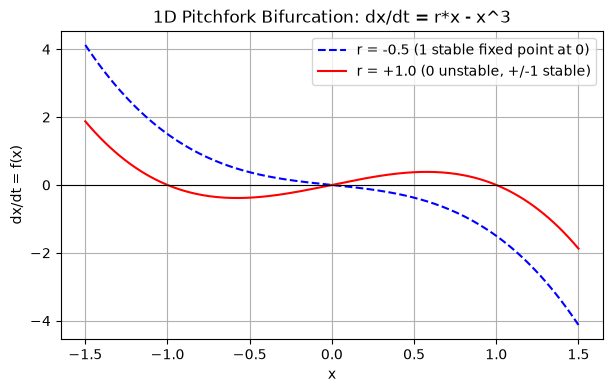

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Graphical analysis: plot f(x) = r*x - x^3 before and after bifurcation
x_grid = np.linspace(-1.5, 1.5, 200)

plt.figure(figsize=(7, 4))
plt.plot(x_grid, -0.5 * x_grid - x_grid**3, 'b--', label='r = -0.5 (1 stable fixed point at 0)')
plt.plot(x_grid,  1.0 * x_grid - x_grid**3, 'r-',  label='r = +1.0 (0 unstable, +/-1 stable)')
plt.axhline(0, color='k', linewidth=0.8)
plt.xlabel('x')
plt.ylabel('dx/dt = f(x)')
plt.title('1D Pitchfork Bifurcation: dx/dt = r*x - x^3')
plt.legend()
plt.grid(True)
plt.show()

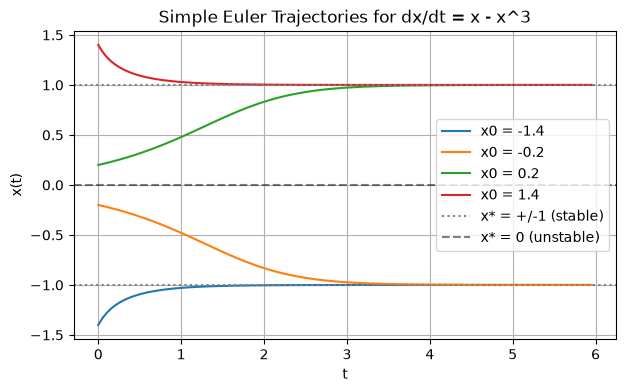

In [2]:
# Simple Euler time evolution for r = 1.0 from different starting points
r = 1.0
dt = 0.05
t = np.arange(0, 6, dt)
n = len(t)

plt.figure(figsize=(7, 4))
for x0 in [-1.4, -0.2, 0.2, 1.4]:
    x = np.zeros(n)
    x[0] = x0
    for i in range(n - 1):
        x[i + 1] = x[i] + dt * (r * x[i] - x[i]**3)
    plt.plot(t, x, label=f'x0 = {x0}')

plt.axhline( 1.0, color='gray', linestyle=':', label='x* = +/-1 (stable)')
plt.axhline(-1.0, color='gray', linestyle=':')
plt.axhline( 0.0, color='k', linestyle='--', alpha=0.5, label='x* = 0 (unstable)')
plt.xlabel('t')
plt.ylabel('x(t)')
plt.title('Simple Euler Trajectories for dx/dt = x - x^3')
plt.legend()
plt.grid(True)
plt.show()

---
## Exam Note: Finding Fixed Points Numerically Using 1D Newton-Raphson (Premid Fallback)
If $f(x^*) = 0$ cannot be factored easily by hand (like $rx - \ln(1+x) = 0$ in Problem Set II Q2), use 1D Newton-Raphson from Premid (`Notes/premid/Root Finding Methods.ipynb`):
$$x_{k+1} = x_k - \frac{f(x_k)}{f'(x_k)}$$

In [3]:
# Quick 1D Newton check to find non-zero fixed point of dx/dt = 1.3*x - ln(1 + x)
x_root = -0.5
for step in range(15):
    fx = 1.3 * x_root - np.log(1.0 + x_root)
    fpx = 1.3 - 1.0 / (1.0 + x_root)
    x_root = x_root - fx / fpx

print(f'Non-zero fixed point x* = {x_root:.6f}')
print(f'Check f(x*) = {1.3 * x_root - np.log(1.0 + x_root):.2e}')

Non-zero fixed point x* = -0.422970
Check f(x*) = 0.00e+00
